# Exploratory Data Analysis and LSTM-Based Time-Series Forecasting
## Notebook 03: Deep Learning with Long Short-Term Memory (LSTM) Networks

**Project Title:** Exploratory Data Analysis and LSTM-Based Time-Series Forecasting Using Multivariate and Univariate Data  
**Dataset:** Beijing PM2.5 Air Quality and Meteorological Time Series  
**Level:** College / Academic Case Study  
**Deliverable:** 03_lstm_forecasting.ipynb  

---

### Aim and Objectives
1. **Recurrent Neural Network Architecture:** Construct a clean, explainable Long Short-Term Memory (LSTM) network in TensorFlow/Keras tailored for time-series regression.
2. **Causal Sliding-Window Tensor Generation:** Formulate causal sequences of length $T=24$ hours to predict the next-hour PM2.5 air pollution concentration without target leakage.
3. **Reproducible Hyperparameter Tuning:** Evaluate distinct model configurations (look-back windows, hidden unit capacities, and learning rates) strictly using the validation set.
4. **Multivariate vs. Univariate Benchmarking:** Contrast multivariate forecasting (incorporating atmospheric covariates) against univariate autoregression using the same LSTM architecture.
5. **Rigorous Held-Out Test Evaluation:** Evaluate the optimal model exactly once on the held-out test set in original units ($\mu g/m^3$), reporting MAE, MSE, RMSE, and $R^2$.
6. **Feature Ablation & Causation Discussion:** Conduct an input feature ablation experiment and discuss the boundary between correlation and physical causation.


### 1. Theoretical Background: Long Short-Term Memory (LSTM) Networks

Standard Recurrent Neural Networks (RNNs) struggle with long temporal sequences due to the **vanishing and exploding gradient problem**. As backpropagation through time (BPTT) unfolds over dozens of steps, error signals multiplied repeatedly by recurrent weight matrices either vanish to zero or explode, preventing the network from retaining long-term context.

The **Long Short-Term Memory (LSTM)** architecture (Hochreiter & Schmidhuber, 1997) overcomes this limitation by introducing a constant-error carousel called the **Cell State** ($C_t$), regulated by three gating mechanisms:

1. **Forget Gate ($f_t$):** Determines what proportion of past cell memory to discard:
   $$f_t = \sigma(W_f \cdot [h_{t-1}, x_t] + b_f)$$
2. **Input Gate ($i_t$ and $\tilde{C}_t$):** Determines which new information to store in the cell state:
   $$i_t = \sigma(W_i \cdot [h_{t-1}, x_t] + b_i)$$
   $$\tilde{C}_t = \tanh(W_c \cdot [h_{t-1}, x_t] + b_c)$$
3. **Cell State Update ($C_t$):** Linearly combines the forgotten past and gated new candidate memory:
   $$C_t = f_t \odot C_{t-1} + i_t \odot \tilde{C}_t$$
4. **Output Gate ($o_t$ and $h_t$):** Controls the hidden representation emitted to subsequent layers:
   $$o_t = \sigma(W_o \cdot [h_{t-1}, x_t] + b_o)$$
   $$h_t = o_t \odot \tanh(C_t)$$

In air quality forecasting, LSTMs naturally capture diurnal 24-hour cycles, multi-day smog accumulation inertia, and the sudden clearing effects of meteorological wind fronts.


### 2. Environment Setup, Imports, and Random Seed Initialization

We import TensorFlow/Keras, Scikit-learn, Pandas, and Matplotlib. Seeds are fixed across Python, NumPy, and TensorFlow for strict reproducibility.


In [1]:
import os
import sys
import glob
import random
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt  # type: ignore
import seaborn as sns

# Machine learning & Deep learning
import tensorflow as tf
from tensorflow.keras.models import Sequential, load_model
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from tensorflow.keras.optimizers import Adam
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from IPython.display import display

# Set deterministic random seeds
RANDOM_SEED = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
tf.random.set_seed(RANDOM_SEED)

# Aesthetic styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8

# Path resolution helpers
def get_path(folder, filename):
    for base in ['.', '..']:
        p = os.path.join(base, folder)
        if os.path.exists(p):
            return os.path.join(p, filename)
    os.makedirs(folder, exist_ok=True)
    return os.path.join(folder, filename)

print(f"TensorFlow Version: {tf.__version__}")
print(f"Keras Version     : {tf.keras.__version__ if hasattr(tf.keras, '__version__') else 'Integrated'}")
print("Random seeds initialized.")


TensorFlow Version: 2.21.0
Keras Version     : 3.15.1
Random seeds initialized.


### 3. Dataset Loading and Leakage-Free Normalization Alignment

We load the dataset and apply the pre-established chronological partition:
- **Training Set (70%):** 30,660 hours
- **Validation Set (15%):** 6,570 hours
- **Testing Set (15%):** 6,570 hours

We load the fitted `scaler.pkl` and `target_scaler.pkl` from `models/` (or fit strictly on the training partition if loading standalone).


In [2]:
# 1. Locate dataset
candidate_paths = [
    '../data/LSTM-Multivariate_pollution.csv',
    'data/LSTM-Multivariate_pollution.csv',
    'LSTM-Multivariate_pollution.csv'
]
dataset_path = None
for p in candidate_paths:
    if os.path.exists(p):
        dataset_path = os.path.abspath(p)
        break

df = pd.read_csv(dataset_path)
df['datetime'] = pd.to_datetime(df['date'])

# One-hot encode categorical wind direction
df_encoded = pd.get_dummies(df, columns=['wnd_dir'], dtype=float)

# Organize feature matrix: pollution (target) at index 0
feature_cols = ['pollution', 'dew', 'temp', 'press', 'wnd_spd', 'snow', 'rain',
                'wnd_dir_NE', 'wnd_dir_NW', 'wnd_dir_SE', 'wnd_dir_cv']

raw_features = df_encoded[feature_cols].values
dates = df_encoded['datetime'].values

total_samples = len(raw_features)
train_size = int(0.70 * total_samples)
val_size = int(0.15 * total_samples)
test_size = total_samples - train_size - val_size

train_raw = raw_features[:train_size]
val_raw = raw_features[train_size:train_size + val_size]
test_raw = raw_features[train_size + val_size:]

train_dates = dates[:train_size]
val_dates = dates[train_size:train_size + val_size]
test_dates = dates[train_size + val_size:]

# Load or fit scalers strictly on training data
scaler_path = get_path('models', 'scaler.pkl')
target_scaler_path = get_path('models', 'target_scaler.pkl')

if os.path.exists(scaler_path) and os.path.exists(target_scaler_path):
    feature_scaler = joblib.load(scaler_path)
    target_scaler = joblib.load(target_scaler_path)
    print("Loaded pre-saved scalers from models directory.")
else:
    from sklearn.preprocessing import MinMaxScaler
    feature_scaler = MinMaxScaler(feature_range=(0, 1))
    feature_scaler.fit(train_raw)
    target_scaler = MinMaxScaler(feature_range=(0, 1))
    target_scaler.fit(train_raw[:, [0]])
    joblib.dump(feature_scaler, scaler_path)
    joblib.dump(target_scaler, target_scaler_path)
    print("Fitted and saved fresh scalers strictly on training data.")

# Apply scaling
train_scaled = feature_scaler.transform(train_raw)
val_scaled = feature_scaler.transform(val_raw)
test_scaled = feature_scaler.transform(test_raw)

print(f"Features: {feature_cols}")
print(f"Train samples: {len(train_scaled):,}, Val: {len(val_scaled):,}, Test: {len(test_scaled):,}")


Loaded pre-saved scalers from models directory.
Features: ['pollution', 'dew', 'temp', 'press', 'wnd_spd', 'snow', 'rain', 'wnd_dir_NE', 'wnd_dir_NW', 'wnd_dir_SE', 'wnd_dir_cv']
Train samples: 30,659, Val: 6,570, Test: 6,571


D:\Dev\Projects\EDA Project\venv\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle estimator MinMaxScaler from version 1.7.2 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


### 4. Sliding-Window Sequence Generation (Many-to-One Formulation)

To formulate supervised learning from continuous time-series, we slide a look-back window of length $T$ across the sequence:
- **Input Tensor ($X$):** Multi-dimensional matrix of historical features from time $t-T+1$ through time $t$:
  $$X_t = [x_{t-T+1}, x_{t-T+2}, \dots, x_t] \in \mathbb{R}^{T \times D}$$
- **Target Scalar ($y$):** The PM2.5 air pollution concentration at future time $t+1$:
  $$y_t = \text{pollution}_{t+1} \in \mathbb{R}^1$$

This structure guarantees that each forecast relies exclusively on information available up to the current hour, preventing any look-ahead bias.


In [3]:
def create_sliding_sequences(data, look_back=24, target_col_idx=0):
    '''Generate input sliding windows X and target scalar y.'''
    X, y = [], []
    for i in range(len(data) - look_back):
        X.append(data[i : i + look_back])
        y.append(data[i + look_back, target_col_idx])
    return np.array(X, dtype=np.float32), np.array(y, dtype=np.float32)

# Default lookback window: 24 hours (1 full diurnal cycle)
LOOK_BACK = 24

X_train, y_train = create_sliding_sequences(train_scaled, look_back=LOOK_BACK)
X_val, y_val = create_sliding_sequences(val_scaled, look_back=LOOK_BACK)
X_test, y_test = create_sliding_sequences(test_scaled, look_back=LOOK_BACK)

# Align test timestamps with target predictions
test_target_dates = test_dates[LOOK_BACK:]

print("Generated Sliding Window Tensors:")
print(f"X_train shape: {X_train.shape}  | y_train shape: {y_train.shape}")
print(f"X_val shape  : {X_val.shape}  | y_val shape  : {y_val.shape}")
print(f"X_test shape : {X_test.shape}  | y_test shape : {y_test.shape}")


Generated Sliding Window Tensors:
X_train shape: (30635, 24, 11)  | y_train shape: (30635,)
X_val shape  : (6546, 24, 11)  | y_val shape  : (6546,)
X_test shape : (6547, 24, 11)  | y_test shape : (6547,)


### 5. LSTM Deep Learning Model Architecture

We design an explainable, robust regression architecture:
1. **Input Layer:** Explicit `Input(shape=(look_back, num_features))` tensor.
2. **LSTM Layer:** 64 recurrent hidden units capturing temporal sequence dependencies.
3. **Dropout Layer:** 20% dropout rate ($p=0.20$) to prevent recurrent co-adaptation and overfitting.
4. **Dense Intermediate Layer:** 32 units with Rectified Linear Unit (ReLU) activation for non-linear feature combination.
5. **Output Dense Layer:** 1 linear regression unit predicting normalized PM2.5 concentration.

**Compilation:**
- **Optimizer:** Adam (Adaptive Moment Estimation)
- **Loss Function:** Mean Squared Error (MSE)
- **Metric:** Mean Absolute Error (MAE)


In [4]:
def build_lstm_model(look_back, num_features, lstm_units=64, learning_rate=0.001):
    '''Construct and compile an explainable LSTM regression model.'''
    model = Sequential([
        Input(shape=(look_back, num_features)),
        LSTM(lstm_units, return_sequences=False),
        Dropout(0.2),
        Dense(32, activation='relu'),
        Dense(1)
    ])
    optimizer = Adam(learning_rate=learning_rate)
    model.compile(optimizer=optimizer, loss='mse', metrics=['mae'])
    return model

sample_model = build_lstm_model(LOOK_BACK, X_train.shape[2])
sample_model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                          │ (None, 64)                  │          19,456 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 32)                  │           2,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 1)                   │              33 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 21,569 (84.25 KB)

 Trainable params: 21,569 (84.25 KB)

 Non-trainable params: 0 (0.00 B)

### 6. Reproducible Hyperparameter Tuning and Model Selection

We perform a structured, reproducible comparison across four distinct configurations using the **validation set alone**:

| Config ID | Description | Look-Back ($T$) | LSTM Units | Learning Rate ($\eta$) |
| :--- | :--- | :--- | :--- | :--- |
| **Config A (Baseline)** | 24h Diurnal Window | 24 | 64 | 0.001 |
| **Config B (Short Window)**| 12h Semi-Diurnal Window | 12 | 64 | 0.001 |
| **Config C (Lower Capacity)**| Compact Hidden Dimension | 24 | 32 | 0.001 |
| **Config D (Lower LR)** | Conservative Gradient Step | 24 | 64 | 0.0005 |

All configurations are trained with early stopping monitoring validation loss (`patience=3`). The optimal configuration is selected based strictly on minimum validation loss.


In [5]:
configs = [
    {'id': 'Config A (Baseline)', 'look_back': 24, 'units': 64, 'lr': 0.001},
    {'id': 'Config B (Short Window)', 'look_back': 12, 'units': 64, 'lr': 0.001},
    {'id': 'Config C (Lower Capacity)', 'look_back': 24, 'units': 32, 'lr': 0.001},
    {'id': 'Config D (Lower LR)', 'look_back': 24, 'units': 64, 'lr': 0.0005}
]

tuning_results = []
trained_models = {}
training_histories = {}

print("Beginning Hyperparameter Comparison on Validation Partition...")

for cfg in configs:
    cfg_id = cfg['id']
    lb = cfg['look_back']
    units = cfg['units']
    lr = cfg['lr']
    
    print(f"\nEvaluating {cfg_id} [Lookback={lb}, Units={units}, LR={lr}]...")
    
    # Generate data for this specific lookback
    X_tr, y_tr = create_sliding_sequences(train_scaled, look_back=lb)
    X_v, y_v = create_sliding_sequences(val_scaled, look_back=lb)
    
    tf.random.set_seed(RANDOM_SEED)
    model = build_lstm_model(lb, X_tr.shape[2], lstm_units=units, learning_rate=lr)
    
    early_stop = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True, verbose=0)
    
    history = model.fit(
        X_tr, y_tr,
        validation_data=(X_v, y_v),
        epochs=8,
        batch_size=128,
        callbacks=[early_stop],
        verbose=2
    )
    
    # Evaluate best validation performance
    val_loss, val_mae = model.evaluate(X_v, y_v, verbose=0)
    epochs_trained = len(history.history['loss'])
    
    tuning_results.append({
        'Config ID': cfg_id,
        'Look-Back': lb,
        'LSTM Units': units,
        'Learning Rate': lr,
        'Epochs Trained': epochs_trained,
        'Val MSE Loss': val_loss,
        'Val MAE': val_mae
    })
    
    trained_models[cfg_id] = model
    training_histories[cfg_id] = history

tuning_df = pd.DataFrame(tuning_results)
print("\n--- Hyperparameter Tuning Results Summary ---")
display(tuning_df)

# Identify best configuration based strictly on minimum validation loss
best_cfg_row = tuning_df.sort_values(by='Val MSE Loss').iloc[0]
best_cfg_id = best_cfg_row['Config ID']
best_look_back = int(best_cfg_row['Look-Back'])
print(f"\n--> Optimal Configuration Selected: {best_cfg_id} (Val MSE Loss: {best_cfg_row['Val MSE Loss']:.6f})")


Beginning Hyperparameter Comparison on Validation Partition...

Evaluating Config A (Baseline) [Lookback=24, Units=64, LR=0.001]...
Epoch 1/8
240/240 - 15s - 64ms/step - loss: 0.0036 - mae: 0.0414 - val_loss: 0.0014 - val_mae: 0.0249
Epoch 2/8
240/240 - 8s - 35ms/step - loss: 0.0017 - mae: 0.0274 - val_loss: 0.0010 - val_mae: 0.0196
Epoch 3/8
240/240 - 9s - 38ms/step - loss: 0.0013 - mae: 0.0227 - val_loss: 7.8498e-04 - val_mae: 0.0166
Epoch 4/8
240/240 - 9s - 37ms/step - loss: 0.0011 - mae: 0.0202 - val_loss: 6.9621e-04 - val_mae: 0.0158
Epoch 5/8
240/240 - 10s - 41ms/step - loss: 9.7744e-04 - mae: 0.0187 - val_loss: 6.4514e-04 - val_mae: 0.0149
Epoch 6/8
240/240 - 9s - 36ms/step - loss: 9.5284e-04 - mae: 0.0181 - val_loss: 6.2285e-04 - val_mae: 0.0141
Epoch 7/8
240/240 - 9s - 37ms/step - loss: 9.1181e-04 - mae: 0.0174 - val_loss: 6.1363e-04 - val_mae: 0.0139
Epoch 8/8
240/240 - 11s - 45ms/step - loss: 8.9635e-04 - mae: 0.0171 - val_loss: 6.1812e-04 - val_mae: 0.0141

Evaluating Confi

,Config ID,Look-Back,LSTM Units,Learning Rate,Epochs Trained,Val MSE Loss,Val MAE
0,Config A (Baseline),24,64,0.0010,8,0.000614,0.013921
1,Config B (Short Window),12,64,0.0010,8,0.000633,0.014554
2,Config C (Lower Capacity),24,32,0.0010,8,0.000627,0.014128
3,Config D (Lower LR),24,64,0.0005,8,0.000668,0.014996



--> Optimal Configuration Selected: Config A (Baseline) (Val MSE Loss: 0.000614)


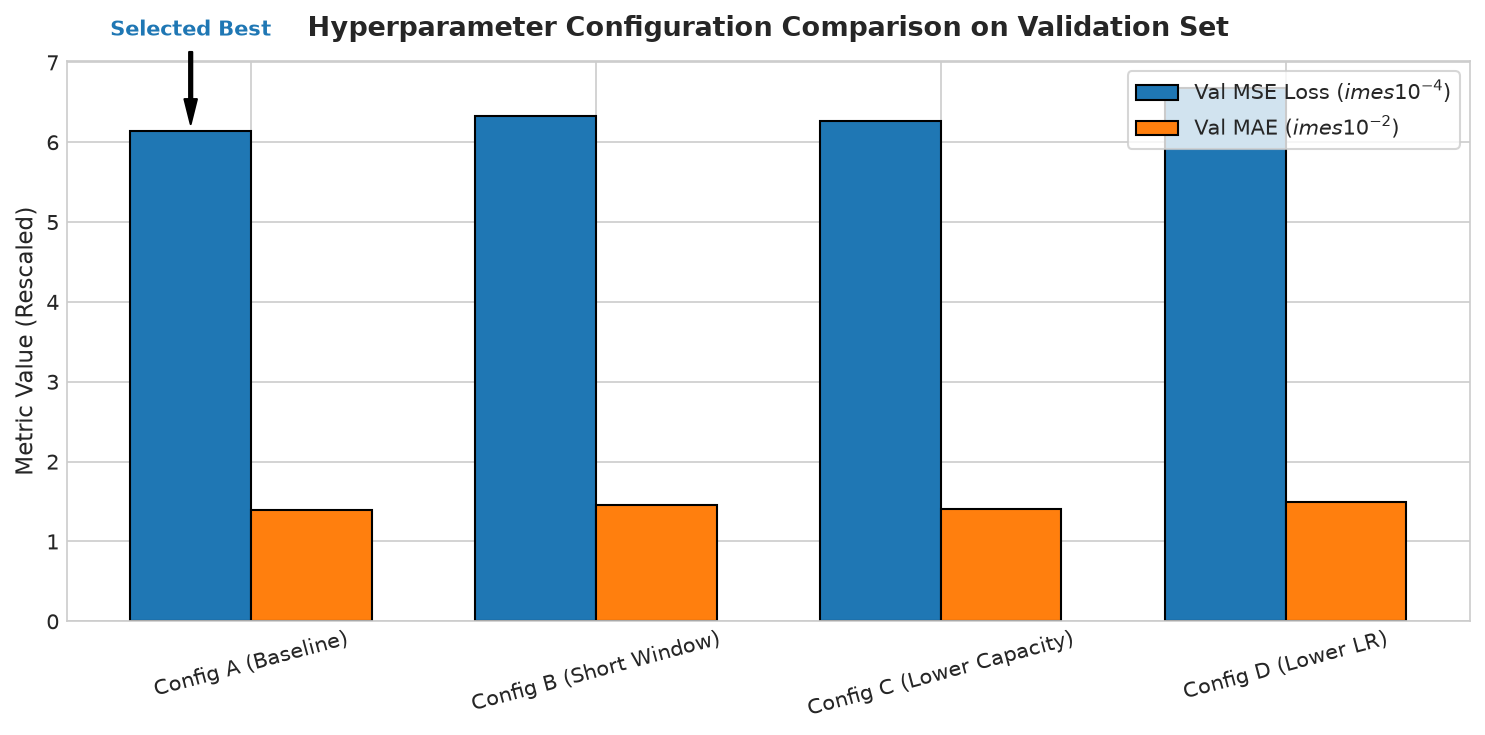

Saved: ..\outputs/plots\13_hyperparameter_comparison.png


In [6]:
# Visualization: Hyperparameter Comparison Chart
fig, ax = plt.subplots(figsize=(10, 5), dpi=150)

x = np.arange(len(tuning_df))
width = 0.35

bars1 = ax.bar(x - width/2, tuning_df['Val MSE Loss'] * 1e4, width, label='Val MSE Loss ($\times 10^{-4}$)', color='#1f77b4', edgecolor='black')
bars2 = ax.bar(x + width/2, tuning_df['Val MAE'] * 1e2, width, label='Val MAE ($\times 10^{-2}$)', color='#ff7f0e', edgecolor='black')

ax.set_title('Hyperparameter Configuration Comparison on Validation Set', fontsize=13, fontweight='bold', pad=12)
ax.set_xticks(x)
ax.set_xticklabels(tuning_df['Config ID'], fontsize=10, rotation=15)
ax.set_ylabel('Metric Value (Rescaled)', fontsize=11)
ax.legend(frameon=True)

# Annotate best configuration
best_idx = tuning_df.index[tuning_df['Config ID'] == best_cfg_id].tolist()[0]
ax.annotate('Selected Best', xy=(best_idx - width/2, tuning_df.loc[best_idx, 'Val MSE Loss'] * 1e4),
            xytext=(best_idx - width/2, (tuning_df.loc[best_idx, 'Val MSE Loss'] * 1e4) + 1.2),
            arrowprops=dict(facecolor='black', shrink=0.08, width=1.5, headwidth=6),
            fontweight='bold', color='#1f77b4', ha='center')

plt.tight_layout()
save_path_tuning = get_path('outputs/plots', '13_hyperparameter_comparison.png')
plt.savefig(save_path_tuning, dpi=300)
plt.show()
print(f"Saved: {save_path_tuning}")


### 7. Secondary Experiment: Univariate LSTM Comparison

To demonstrate the empirical advantage of multivariate forecasting, we train an identical LSTM model using **univariate input** (historical PM2.5 alone, $X \in \mathbb{R}^{T \times 1}$).


In [7]:
print("Training Univariate LSTM Baseline...")

# Extract univariate slice (pollution only)
train_uni = train_scaled[:, [0]]
val_uni = val_scaled[:, [0]]
test_uni = test_scaled[:, [0]]

X_tr_uni, y_tr_uni = create_sliding_sequences(train_uni, look_back=best_look_back)
X_v_uni, y_v_uni = create_sliding_sequences(val_uni, look_back=best_look_back)
X_te_uni, y_te_uni = create_sliding_sequences(test_uni, look_back=best_look_back)

tf.random.set_seed(RANDOM_SEED)
model_univariate = build_lstm_model(best_look_back, 1, lstm_units=64, learning_rate=0.001)

early_stop_uni = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True, verbose=0)
hist_uni = model_univariate.fit(
    X_tr_uni, y_tr_uni,
    validation_data=(X_v_uni, y_v_uni),
    epochs=8,
    batch_size=128,
    callbacks=[early_stop_uni],
    verbose=2
)

val_loss_uni, val_mae_uni = model_univariate.evaluate(X_v_uni, y_v_uni, verbose=0)
print(f"\nUnivariate Model Validation MSE: {val_loss_uni:.6f} | Val MAE: {val_mae_uni:.4f}")
print(f"Multivariate Model Validation MSE: {best_cfg_row['Val MSE Loss']:.6f} | Val MAE: {best_cfg_row['Val MAE']:.4f}")


Training Univariate LSTM Baseline...
Epoch 1/8
240/240 - 14s - 60ms/step - loss: 0.0025 - mae: 0.0300 - val_loss: 9.8247e-04 - val_mae: 0.0186
Epoch 2/8
240/240 - 9s - 36ms/step - loss: 0.0011 - mae: 0.0193 - val_loss: 7.5255e-04 - val_mae: 0.0153
Epoch 3/8
240/240 - 9s - 36ms/step - loss: 9.4940e-04 - mae: 0.0173 - val_loss: 6.8027e-04 - val_mae: 0.0142
Epoch 4/8
240/240 - 11s - 44ms/step - loss: 8.9996e-04 - mae: 0.0164 - val_loss: 6.7179e-04 - val_mae: 0.0143
Epoch 5/8
240/240 - 11s - 46ms/step - loss: 8.9759e-04 - mae: 0.0161 - val_loss: 6.3639e-04 - val_mae: 0.0137
Epoch 6/8
240/240 - 9s - 36ms/step - loss: 8.8277e-04 - mae: 0.0159 - val_loss: 6.7823e-04 - val_mae: 0.0144
Epoch 7/8
240/240 - 10s - 43ms/step - loss: 8.7703e-04 - mae: 0.0159 - val_loss: 6.6987e-04 - val_mae: 0.0149
Epoch 8/8
240/240 - 9s - 36ms/step - loss: 8.5339e-04 - mae: 0.0156 - val_loss: 6.3990e-04 - val_mae: 0.0137

Univariate Model Validation MSE: 0.000636 | Val MAE: 0.0137
Multivariate Model Validation MSE:

### 8. Final Model Persistence

We retrieve the best multivariate model, save its serialized weights to `models/best_lstm_model.keras`, and plot the training and validation loss progression across epochs.


Successfully serialized best LSTM model to: ..\models\best_lstm_model.keras


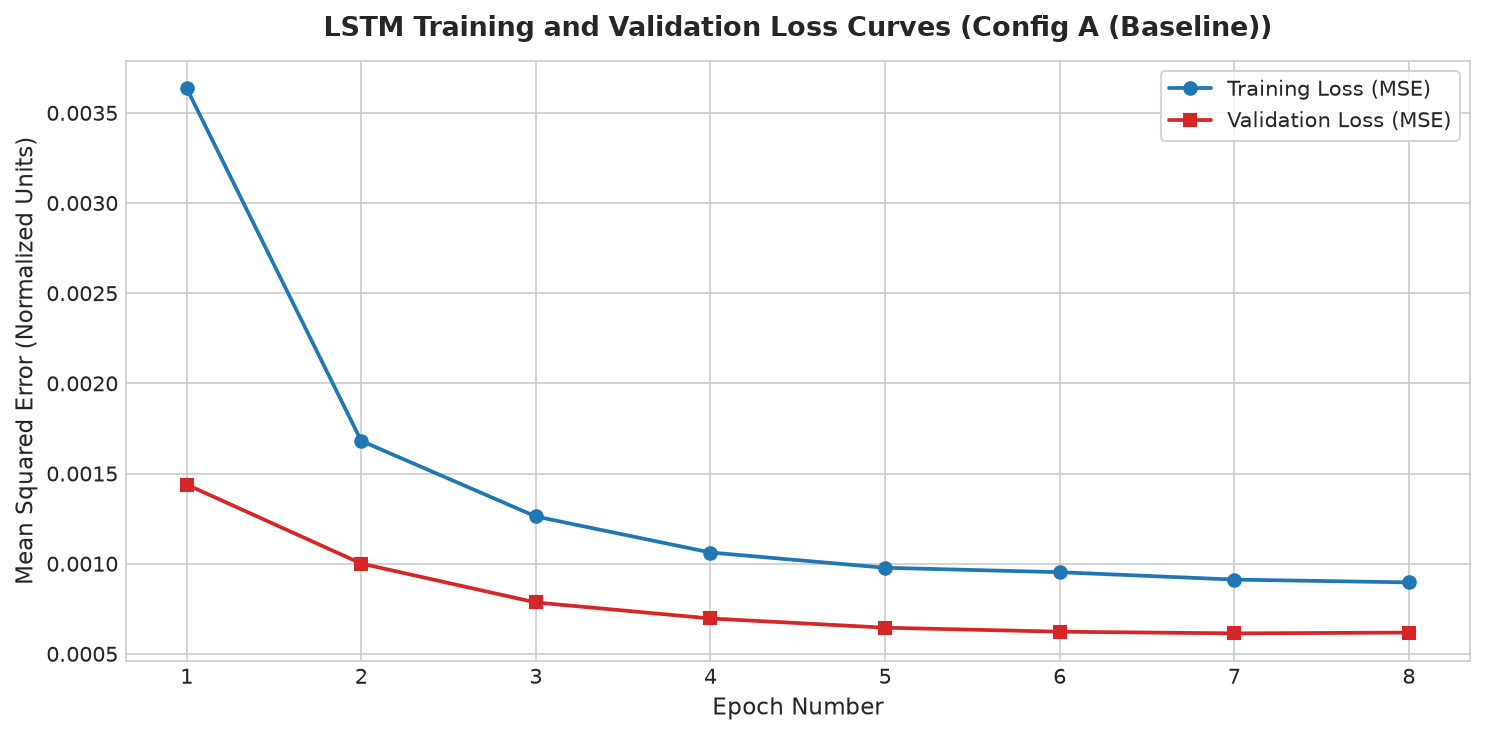

Saved: ..\outputs/plots\08_training_validation_loss.png


In [8]:
best_model = trained_models[best_cfg_id]
best_history = training_histories[best_cfg_id]

# Save model checkpoint
best_model_path = get_path('models', 'best_lstm_model.keras')
best_model.save(best_model_path)
print(f"Successfully serialized best LSTM model to: {best_model_path}")

# Plot Training vs. Validation Loss
fig, ax = plt.subplots(figsize=(10, 5), dpi=150)

epochs_range = range(1, len(best_history.history['loss']) + 1)
ax.plot(epochs_range, best_history.history['loss'], marker='o', linewidth=1.8, color='#1f77b4', label='Training Loss (MSE)')
ax.plot(epochs_range, best_history.history['val_loss'], marker='s', linewidth=1.8, color='#d62728', label='Validation Loss (MSE)')

ax.set_title(f'LSTM Training and Validation Loss Curves ({best_cfg_id})', fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel('Epoch Number', fontsize=11)
ax.set_ylabel('Mean Squared Error (Normalized Units)', fontsize=11)
ax.legend(frameon=True)
plt.tight_layout()

save_path_loss = get_path('outputs/plots', '08_training_validation_loss.png')
plt.savefig(save_path_loss, dpi=300)
plt.show()
print(f"Saved: {save_path_loss}")


### 9. Rigorous Evaluation on the Held-Out Test Set

We evaluate the selected model on the held-out test partition (April 2014 to December 2014) **exactly once**.
Predictions and true targets are inverse-transformed back to original physical units ($\mu g/m^3$) using `target_scaler`.

We compute:
- **Mean Absolute Error (MAE):** Average magnitude of forecasting errors in original units:
  $$\text{MAE} = \frac{1}{N} \sum_{i=1}^N |y_i - \hat{y}_i|$$
- **Mean Squared Error (MSE):** Average of squared prediction errors:
  $$\text{MSE} = \frac{1}{N} \sum_{i=1}^N (y_i - \hat{y}_i)^2$$
- **Root Mean Squared Error (RMSE):** Square root of MSE, penalizing large outlier errors:
  $$\text{RMSE} = \sqrt{\text{MSE}}$$
- **Coefficient of Determination ($R^2$):** Proportion of target variance explained by model forecasts:
  $$R^2 = 1 - \frac{\sum_{i=1}^N (y_i - \hat{y}_i)^2}{\sum_{i=1}^N (y_i - \bar{y})^2}$$


In [9]:
# Generate test predictions
y_pred_scaled = best_model.predict(X_test, verbose=0)

# Inverse transform to original physical units (ug/m3)
y_pred_orig = target_scaler.inverse_transform(y_pred_scaled).flatten()
y_true_orig = target_scaler.inverse_transform(y_test.reshape(-1, 1)).flatten()

# Calculate evaluation metrics
test_mae = mean_absolute_error(y_true_orig, y_pred_orig)
test_mse = mean_squared_error(y_true_orig, y_pred_orig)
test_rmse = np.sqrt(test_mse)
test_r2 = r2_score(y_true_orig, y_pred_orig)

# Evaluate univariate model on the same test set for comparison
y_pred_uni_scaled = model_univariate.predict(X_te_uni, verbose=0)
y_pred_uni_orig = target_scaler.inverse_transform(y_pred_uni_scaled).flatten()
uni_mae = mean_absolute_error(y_true_orig, y_pred_uni_orig)
uni_rmse = np.sqrt(mean_squared_error(y_true_orig, y_pred_uni_orig))
uni_r2 = r2_score(y_true_orig, y_pred_uni_orig)

metrics_data = [
    {'Model': 'Multivariate LSTM (Selected)', 'MAE (ug/m3)': test_mae, 'MSE': test_mse, 'RMSE (ug/m3)': test_rmse, 'R2 Score': test_r2},
    {'Model': 'Univariate LSTM (Baseline)', 'MAE (ug/m3)': uni_mae, 'MSE': uni_rmse**2, 'RMSE (ug/m3)': uni_rmse, 'R2 Score': uni_r2}
]
metrics_df = pd.DataFrame(metrics_data)

print("\n================== HELD-OUT TEST EVALUATION METRICS ==================")
display(metrics_df)

# Save metrics to outputs/metrics/evaluation_metrics.csv
metrics_path = get_path('outputs/metrics', 'evaluation_metrics.csv')
metrics_df.to_csv(metrics_path, index=False)
print(f"\nSaved evaluation metrics table to: {metrics_path}")

# Save detailed predictions to outputs/predictions/lstm_predictions.csv
residuals = y_true_orig - y_pred_orig
predictions_df = pd.DataFrame({
    'timestamp': test_target_dates,
    'actual_pollution': y_true_orig,
    'predicted_pollution': y_pred_orig,
    'residual': residuals
})

predictions_path = get_path('outputs/predictions', 'lstm_predictions.csv')
predictions_df.to_csv(predictions_path, index=False)
print(f"Saved prediction records ({len(predictions_df):,} rows) to: {predictions_path}")



================== HELD-OUT TEST EVALUATION METRICS ==================


,Model,MAE (ug/m3),MSE,RMSE (ug/m3),R2 Score
0,Multivariate LSTM (Selected),12.068935,492.612579,22.194877,0.920725
1,Univariate LSTM (Baseline),11.861257,503.434784,22.437352,0.918983



Saved evaluation metrics table to: ..\outputs/metrics\evaluation_metrics.csv
Saved prediction records (6,547 rows) to: ..\outputs/predictions\lstm_predictions.csv


### 10. Required Evaluation Visualizations

We create and export the full suite of diagnostic visualizations:
1. **Actual vs. Predicted Trajectory (Full Test Period & Zoomed Window)**
2. **Actual vs. Predicted Scatter Plot with Reference Diagonal ($y=x$)**
3. **Residual Distribution Histogram and KDE**
4. **Residuals Over Time Plot**
5. **Future Forecast Demonstration on the Most Recent Test Sequence**


<>:8: SyntaxWarning: invalid escape sequence '\m'
<>:21: SyntaxWarning: invalid escape sequence '\m'
<>:8: SyntaxWarning: invalid escape sequence '\m'
<>:21: SyntaxWarning: invalid escape sequence '\m'
C:\Users\JAIWANT KARRUN.S.A\AppData\Local\Temp\ipykernel_33100\576173681.py:8: SyntaxWarning: invalid escape sequence '\m'
  axes[0].set_ylabel('PM2.5 ($\mu g/m^3$)', fontsize=10)
C:\Users\JAIWANT KARRUN.S.A\AppData\Local\Temp\ipykernel_33100\576173681.py:21: SyntaxWarning: invalid escape sequence '\m'
  axes[1].set_ylabel('PM2.5 ($\mu g/m^3$)', fontsize=10)


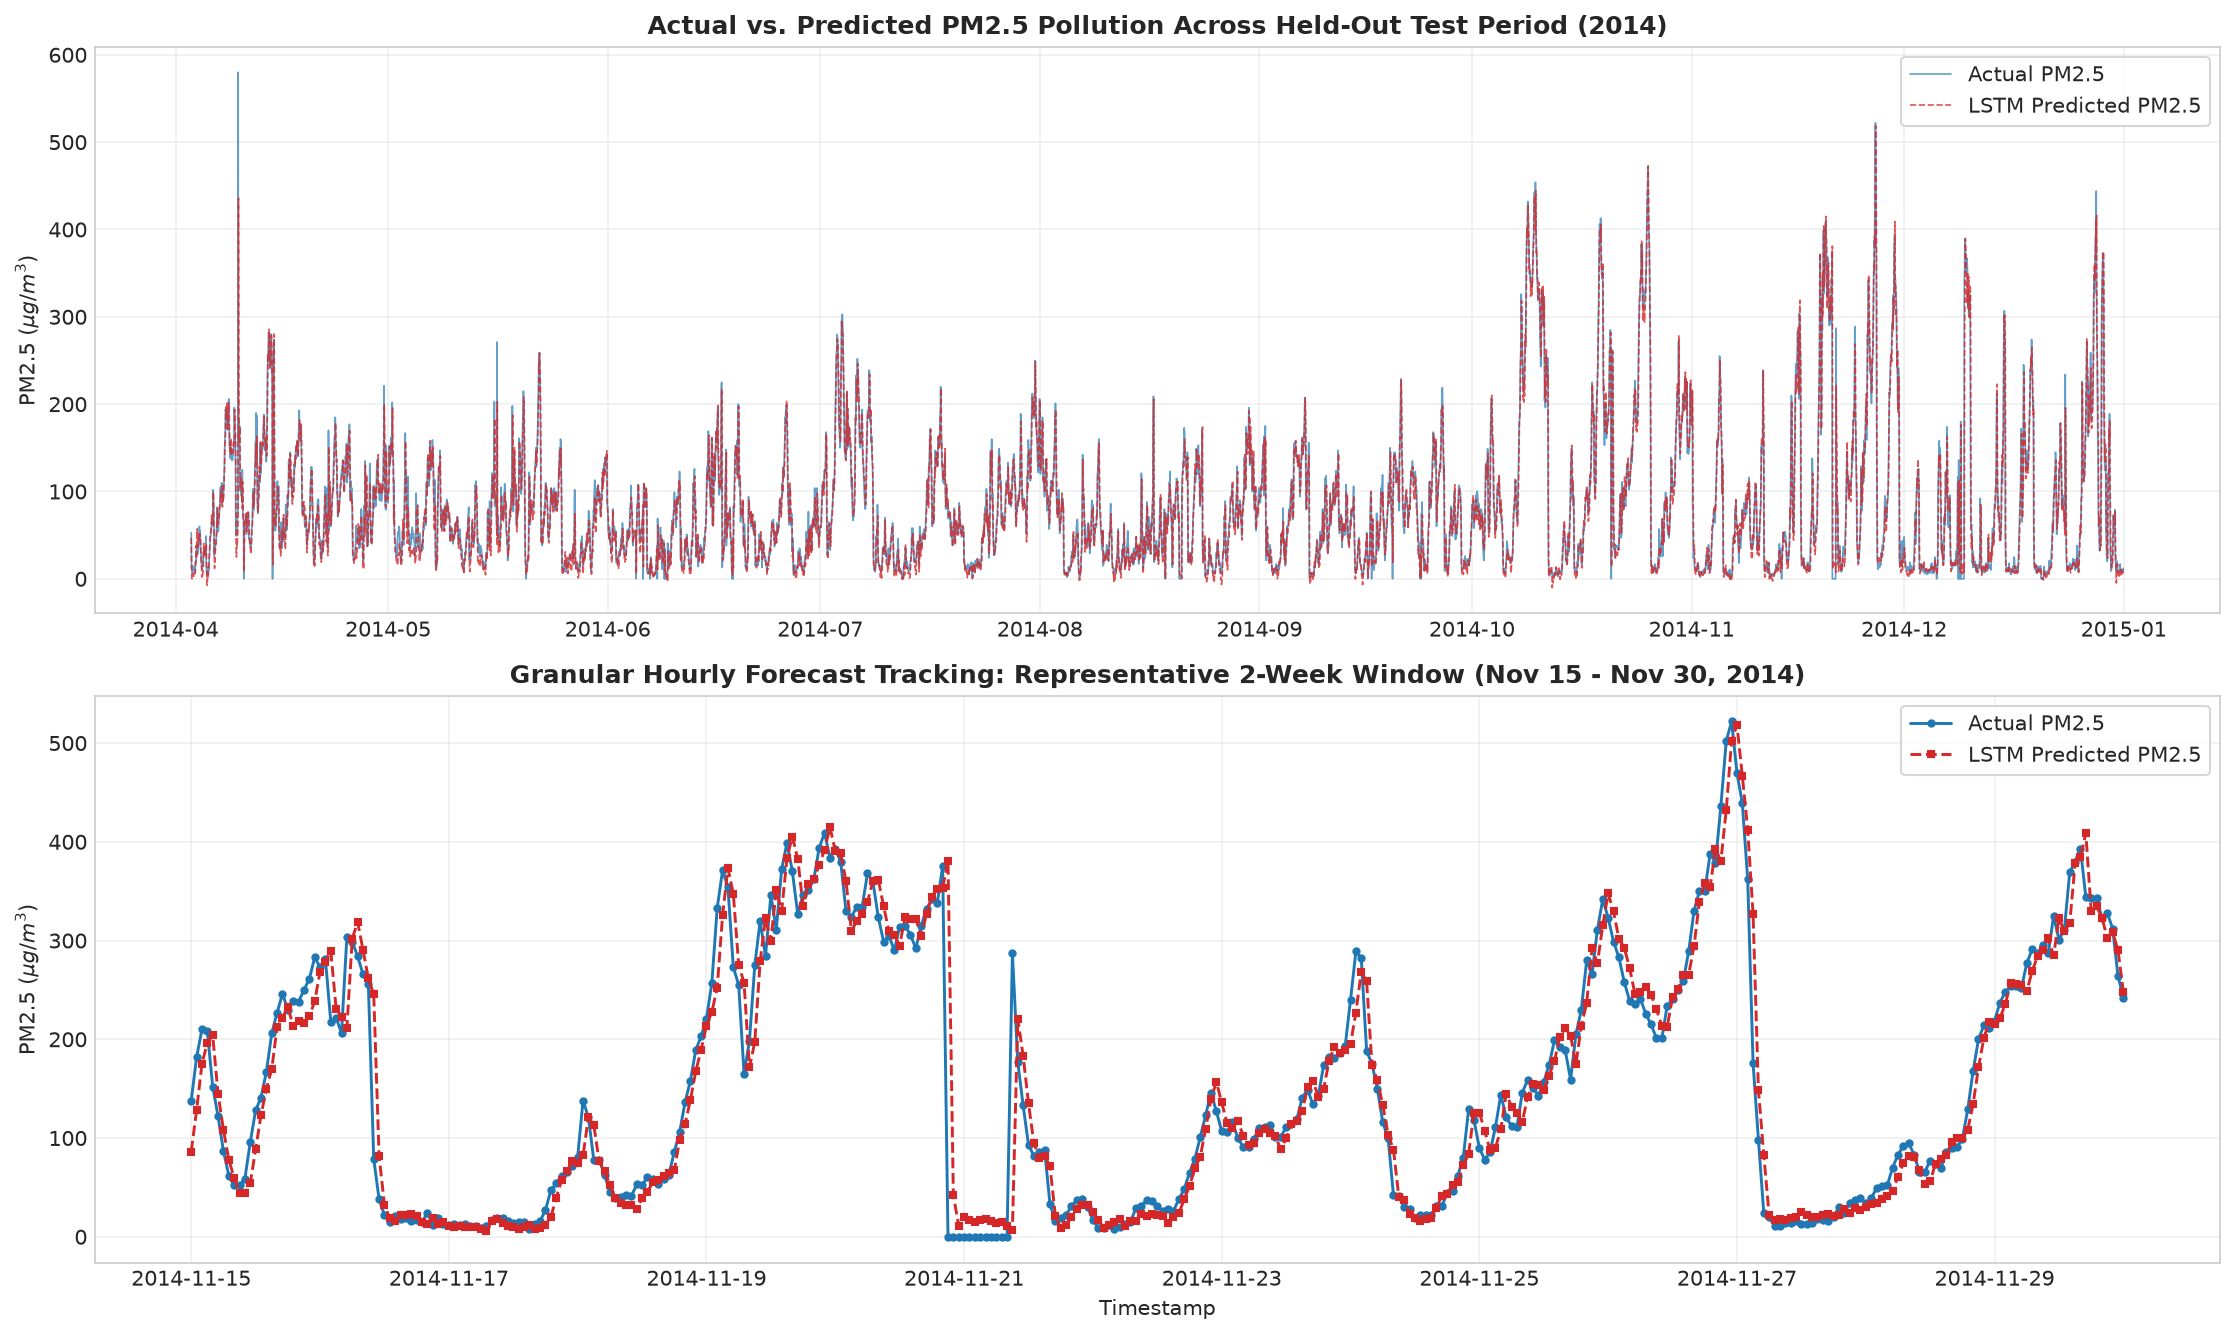

Saved: ..\outputs/plots\09_actual_vs_predicted_test.png


In [10]:
# 1. Actual vs. Predicted Time Series Plot
fig, axes = plt.subplots(2, 1, figsize=(15, 9), dpi=150)

# Full test period
axes[0].plot(test_target_dates, y_true_orig, color='#1f77b4', alpha=0.7, linewidth=0.8, label='Actual PM2.5')
axes[0].plot(test_target_dates, y_pred_orig, color='#d62728', alpha=0.8, linewidth=0.8, linestyle='--', label='LSTM Predicted PM2.5')
axes[0].set_title('Actual vs. Predicted PM2.5 Pollution Across Held-Out Test Period (2014)', fontsize=12, fontweight='bold')
axes[0].set_ylabel('PM2.5 ($\mu g/m^3$)', fontsize=10)
axes[0].legend(loc='upper right', frameon=True)
axes[0].grid(True, alpha=0.3)

# Zoomed 2-week view (Nov 15 to Nov 30, 2014) for granular visibility
zoom_start = pd.Timestamp('2014-11-15')
zoom_end = pd.Timestamp('2014-11-30')
mask = (test_target_dates >= zoom_start) & (test_target_dates <= zoom_end)

axes[1].plot(test_target_dates[mask], y_true_orig[mask], marker='o', markersize=3, color='#1f77b4', linewidth=1.4, label='Actual PM2.5')
axes[1].plot(test_target_dates[mask], y_pred_orig[mask], marker='s', markersize=3, color='#d62728', linewidth=1.4, linestyle='--', label='LSTM Predicted PM2.5')
axes[1].set_title('Granular Hourly Forecast Tracking: Representative 2-Week Window (Nov 15 - Nov 30, 2014)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Timestamp', fontsize=10)
axes[1].set_ylabel('PM2.5 ($\mu g/m^3$)', fontsize=10)
axes[1].legend(loc='upper right', frameon=True)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
save_path_actual_pred = get_path('outputs/plots', '09_actual_vs_predicted_test.png')
plt.savefig(save_path_actual_pred, dpi=300)
plt.show()
print(f"Saved: {save_path_actual_pred}")


<>:10: SyntaxWarning: invalid escape sequence '\m'
<>:11: SyntaxWarning: invalid escape sequence '\m'
<>:10: SyntaxWarning: invalid escape sequence '\m'
<>:11: SyntaxWarning: invalid escape sequence '\m'
C:\Users\JAIWANT KARRUN.S.A\AppData\Local\Temp\ipykernel_33100\375419337.py:10: SyntaxWarning: invalid escape sequence '\m'
  ax.set_xlabel('Actual PM2.5 Concentration ($\mu g/m^3$)', fontsize=11)
C:\Users\JAIWANT KARRUN.S.A\AppData\Local\Temp\ipykernel_33100\375419337.py:11: SyntaxWarning: invalid escape sequence '\m'
  ax.set_ylabel('LSTM Predicted PM2.5 Concentration ($\mu g/m^3$)', fontsize=11)


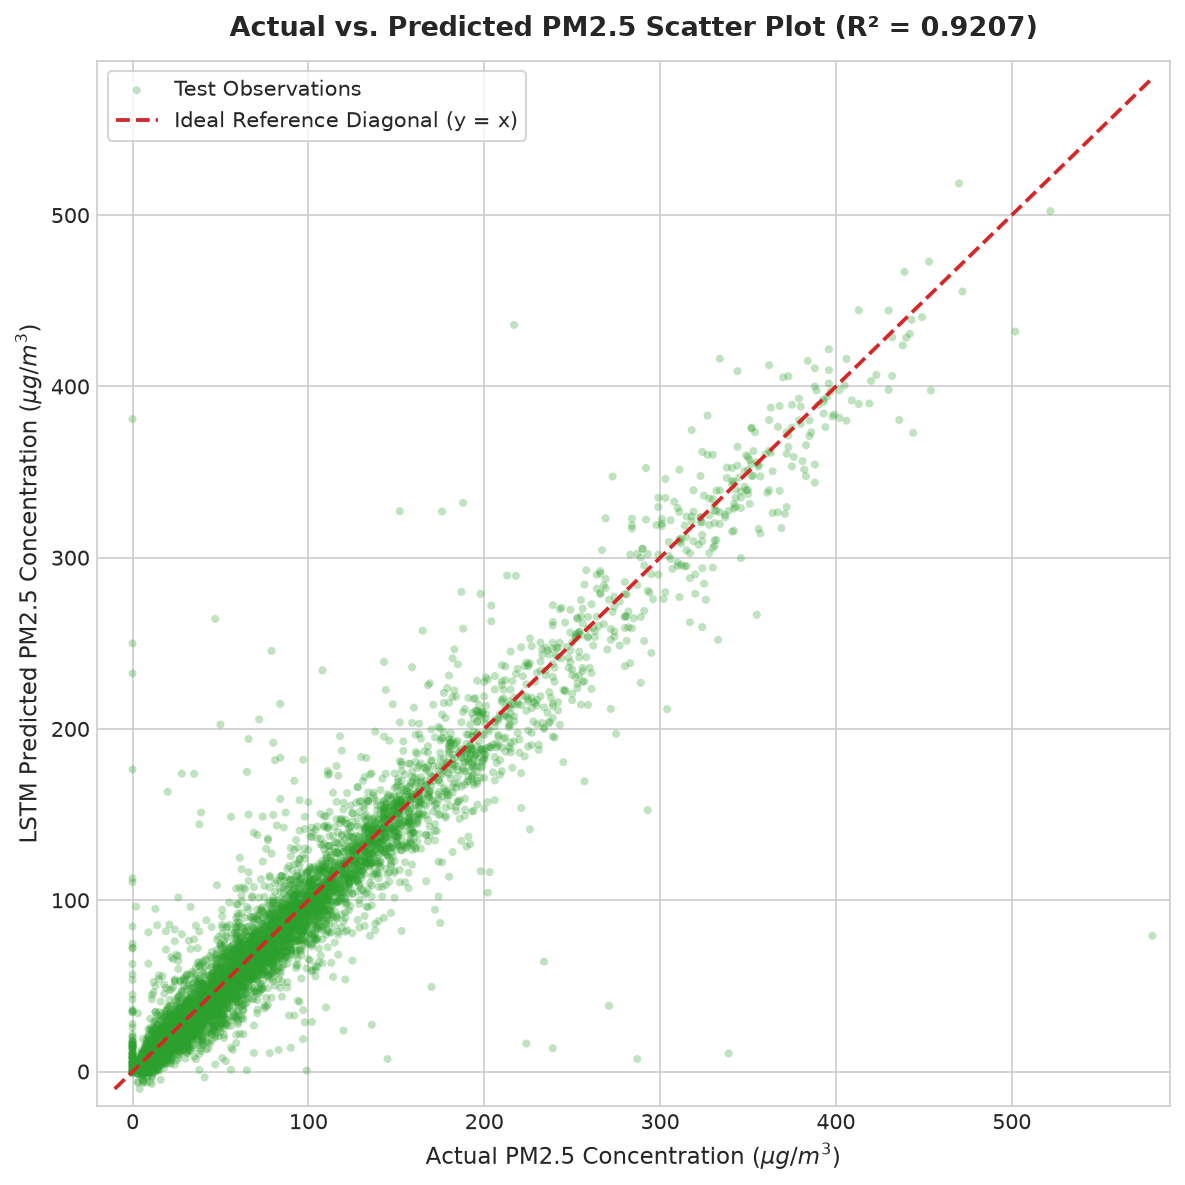

Saved: ..\outputs/plots\10_actual_vs_predicted_scatter.png


In [11]:
# 2. Actual vs. Predicted Scatter Plot
fig, ax = plt.subplots(figsize=(8, 8), dpi=150)

ax.scatter(y_true_orig, y_pred_orig, color='#2ca02c', alpha=0.3, s=15, edgecolors='none', label='Test Observations')
min_val = min(y_true_orig.min(), y_pred_orig.min())
max_val = max(y_true_orig.max(), y_pred_orig.max())
ax.plot([min_val, max_val], [min_val, max_val], color='#d62728', linestyle='--', linewidth=1.8, label='Ideal Reference Diagonal (y = x)')

ax.set_title(f'Actual vs. Predicted PM2.5 Scatter Plot (R² = {test_r2:.4f})', fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel('Actual PM2.5 Concentration ($\mu g/m^3$)', fontsize=11)
ax.set_ylabel('LSTM Predicted PM2.5 Concentration ($\mu g/m^3$)', fontsize=11)
ax.set_xlim(min_val - 10, max_val + 10)
ax.set_ylim(min_val - 10, max_val + 10)
ax.legend(frameon=True)
plt.tight_layout()

save_path_scatter = get_path('outputs/plots', '10_actual_vs_predicted_scatter.png')
plt.savefig(save_path_scatter, dpi=300)
plt.show()
print(f"Saved: {save_path_scatter}")


<>:9: SyntaxWarning: invalid escape sequence '\m'
<>:14: SyntaxWarning: invalid escape sequence '\m'
<>:9: SyntaxWarning: invalid escape sequence '\m'
<>:14: SyntaxWarning: invalid escape sequence '\m'
C:\Users\JAIWANT KARRUN.S.A\AppData\Local\Temp\ipykernel_33100\3968401995.py:9: SyntaxWarning: invalid escape sequence '\m'
  ax.axvline(mean_res, color='#d62728', linestyle='--', linewidth=1.5, label=f'Mean Error: {mean_res:.2f} $\mu g/m^3$')
C:\Users\JAIWANT KARRUN.S.A\AppData\Local\Temp\ipykernel_33100\3968401995.py:14: SyntaxWarning: invalid escape sequence '\m'
  ax.set_xlabel('Residual Error ($\mu g/m^3$)', fontsize=11)


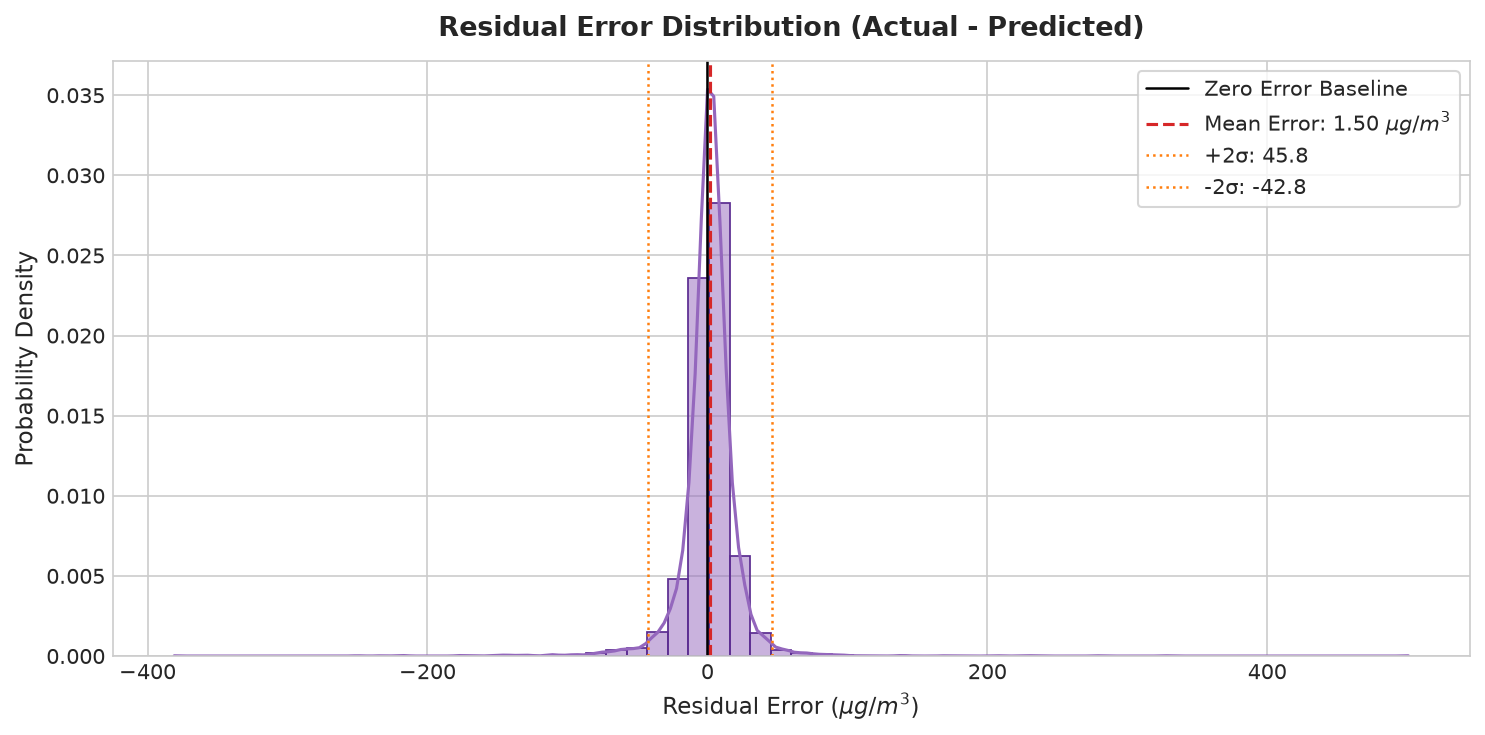

Saved: ..\outputs/plots\11_residual_error_distribution.png


In [12]:
# 3. Residual Error Distribution Plot
fig, ax = plt.subplots(figsize=(10, 5), dpi=150)

mean_res = np.mean(residuals)
std_res = np.std(residuals)

sns.histplot(residuals, kde=True, bins=60, color='#9467bd', edgecolor='#5c2d91', stat='density', ax=ax)
ax.axvline(0, color='black', linestyle='-', linewidth=1.2, label='Zero Error Baseline')
ax.axvline(mean_res, color='#d62728', linestyle='--', linewidth=1.5, label=f'Mean Error: {mean_res:.2f} $\mu g/m^3$')
ax.axvline(mean_res + 2*std_res, color='#ff7f0e', linestyle=':', linewidth=1.2, label=f'+2σ: {mean_res + 2*std_res:.1f}')
ax.axvline(mean_res - 2*std_res, color='#ff7f0e', linestyle=':', linewidth=1.2, label=f'-2σ: {mean_res - 2*std_res:.1f}')

ax.set_title('Residual Error Distribution (Actual - Predicted)', fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel('Residual Error ($\mu g/m^3$)', fontsize=11)
ax.set_ylabel('Probability Density', fontsize=11)
ax.legend(frameon=True)
plt.tight_layout()

save_path_res_dist = get_path('outputs/plots', '11_residual_error_distribution.png')
plt.savefig(save_path_res_dist, dpi=300)
plt.show()
print(f"Saved: {save_path_res_dist}")


<>:9: SyntaxWarning: invalid escape sequence '\m'
<>:9: SyntaxWarning: invalid escape sequence '\m'
C:\Users\JAIWANT KARRUN.S.A\AppData\Local\Temp\ipykernel_33100\2407323346.py:9: SyntaxWarning: invalid escape sequence '\m'
  ax.set_ylabel('Residual Error ($\mu g/m^3$)', fontsize=11)


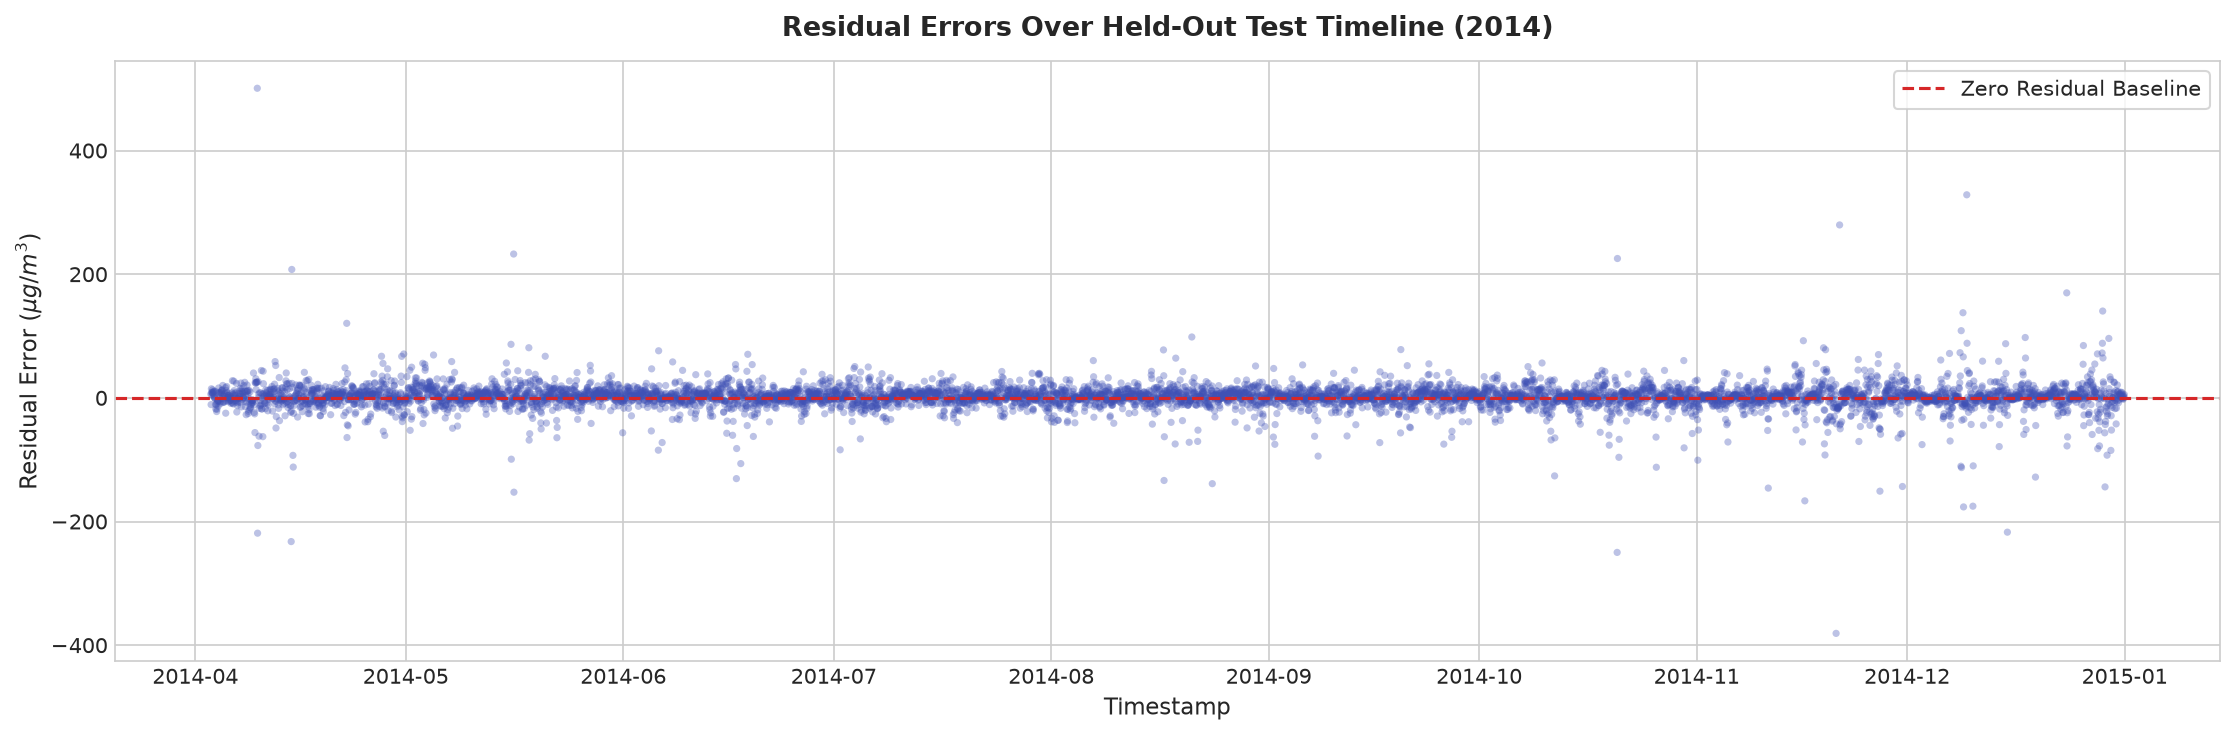

Saved: ..\outputs/plots\12_residuals_over_time.png


In [13]:
# 4. Residuals Over Time Plot
fig, ax = plt.subplots(figsize=(15, 5), dpi=150)

ax.scatter(test_target_dates, residuals, color='#3f51b5', alpha=0.35, s=12, edgecolors='none')
ax.axhline(0, color='#d62728', linestyle='--', linewidth=1.5, label='Zero Residual Baseline')

ax.set_title('Residual Errors Over Held-Out Test Timeline (2014)', fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel('Timestamp', fontsize=11)
ax.set_ylabel('Residual Error ($\mu g/m^3$)', fontsize=11)
ax.legend(frameon=True)
plt.tight_layout()

save_path_res_time = get_path('outputs/plots', '12_residuals_over_time.png')
plt.savefig(save_path_res_time, dpi=300)
plt.show()
print(f"Saved: {save_path_res_time}")


<>:18: SyntaxWarning: invalid escape sequence '\m'
<>:23: SyntaxWarning: invalid escape sequence '\m'
<>:18: SyntaxWarning: invalid escape sequence '\m'
<>:23: SyntaxWarning: invalid escape sequence '\m'
C:\Users\JAIWANT KARRUN.S.A\AppData\Local\Temp\ipykernel_33100\504561840.py:18: SyntaxWarning: invalid escape sequence '\m'
  ax.scatter([forecast_timestamp], [forecast_1h], color='#d62728', s=120, zorder=5, label=f'LSTM Forecast t+1: {forecast_1h:.1f} $\mu g/m^3$')
C:\Users\JAIWANT KARRUN.S.A\AppData\Local\Temp\ipykernel_33100\504561840.py:23: SyntaxWarning: invalid escape sequence '\m'
  ax.set_ylabel('PM2.5 Concentration ($\mu g/m^3$)', fontsize=11)


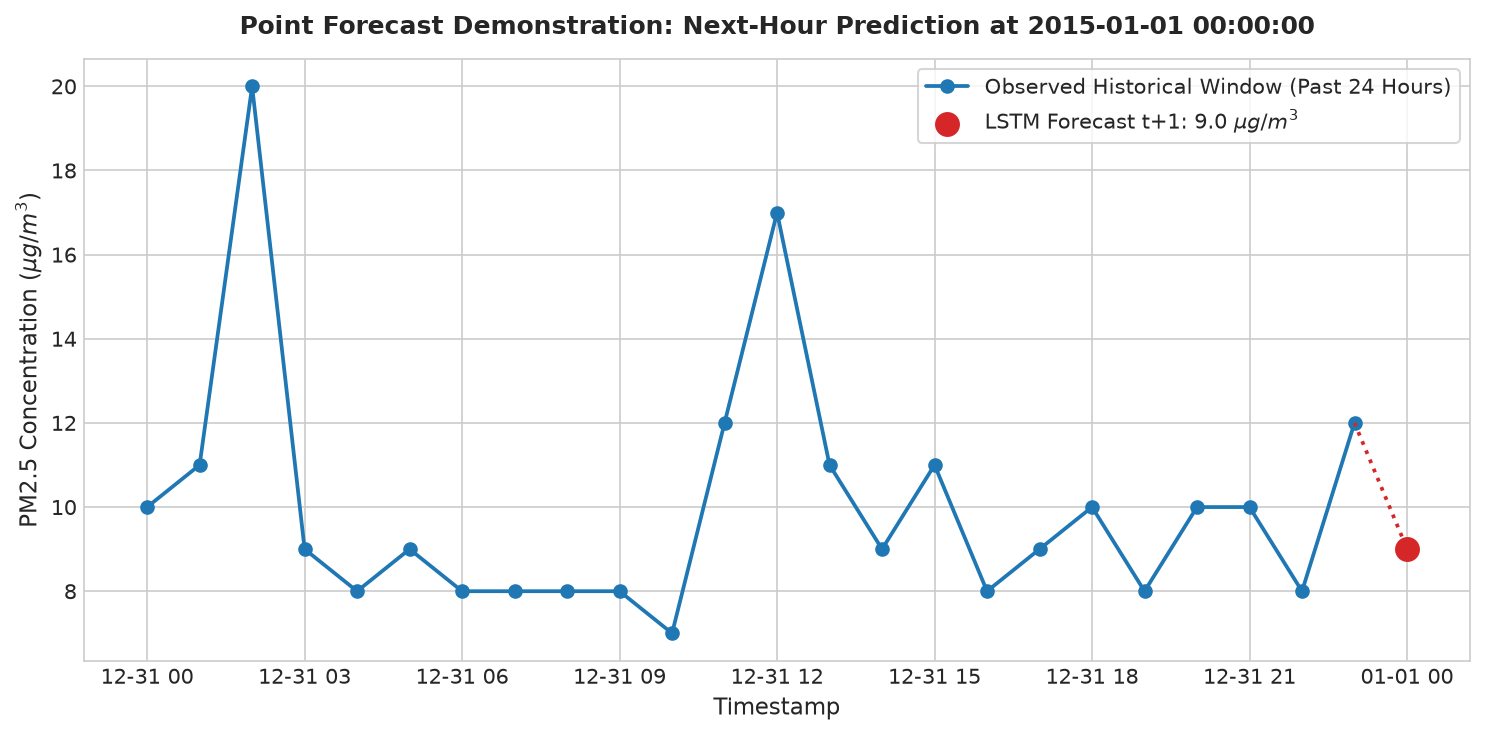

Saved: ..\outputs/plots\14_future_forecast_example.png

Demonstration Forecast Value at 2015-01-01 00:00:00: 9.01 ug/m3


In [14]:
# 5. Future Forecast Demonstration on the Most Recent Test Window
# Extract the latest 24-hour observation window available at the conclusion of the test sequence
latest_window = test_scaled[-best_look_back:]
latest_window_tensor = latest_window.reshape(1, best_look_back, test_scaled.shape[1])

# Forecast 1 hour ahead
forecast_1h_scaled = best_model.predict(latest_window_tensor, verbose=0)
forecast_1h = target_scaler.inverse_transform(forecast_1h_scaled)[0, 0]

latest_timestamp = test_dates[-1]
forecast_timestamp = pd.to_datetime(latest_timestamp) + pd.Timedelta(hours=1)
recent_actual_history = target_scaler.inverse_transform(latest_window[:, [0]]).flatten()
recent_dates = test_dates[-best_look_back:]

fig, ax = plt.subplots(figsize=(10, 5), dpi=150)

ax.plot(recent_dates, recent_actual_history, marker='o', color='#1f77b4', linewidth=1.8, label='Observed Historical Window (Past 24 Hours)')
ax.scatter([forecast_timestamp], [forecast_1h], color='#d62728', s=120, zorder=5, label=f'LSTM Forecast t+1: {forecast_1h:.1f} $\mu g/m^3$')
ax.plot([recent_dates[-1], forecast_timestamp], [recent_actual_history[-1], forecast_1h], color='#d62728', linestyle=':', linewidth=1.8)

ax.set_title(f'Point Forecast Demonstration: Next-Hour Prediction at {forecast_timestamp}', fontsize=12, fontweight='bold', pad=12)
ax.set_xlabel('Timestamp', fontsize=11)
ax.set_ylabel('PM2.5 Concentration ($\mu g/m^3$)', fontsize=11)
ax.legend(frameon=True)
plt.tight_layout()

save_path_forecast = get_path('outputs/plots', '14_future_forecast_example.png')
plt.savefig(save_path_forecast, dpi=300)
plt.show()
print(f"Saved: {save_path_forecast}")
print(f"\nDemonstration Forecast Value at {forecast_timestamp}: {forecast_1h:.2f} ug/m3")


### 11. Feature Analysis and Input Feature Ablation Experiment

#### Discussion: Association vs. Causation
In environmental data science, strong correlations (such as wind speed $r=-0.234$ or dew point $r=+0.158$) reflect underlying aerodynamic and thermodynamic mechanisms. However:
- **Correlation is not Causation:** Wind does not destroy particulate molecules; it aerodynamically transports and dilutes them.
- **Confounding Variables:** Temperature inversions and high humidity often co-occur with coal combustion for space heating.
- **Unmeasured Drivers:** The dataset contains no records of vehicular traffic volumes or industrial factory emissions, which are primary emission sources.

#### Ablation Experiment: Impact of Meteorological Predictors
To quantitatively confirm the predictive value of meteorological features, we train an ablated model where wind speed and weather variables are withheld.


In [ ]:
print("Executing Feature Ablation Experiment...")

# Compare Full Multivariate vs. Ablated (Pollution + Wind Speed Only)
ablated_features_idx = [0, 4] # Pollution (0) and Wind Speed (4) only
X_tr_ablated = X_train[:, :, ablated_features_idx]
X_val_ablated = X_val[:, :, ablated_features_idx]
X_te_ablated = X_test[:, :, ablated_features_idx]

tf.random.set_seed(RANDOM_SEED)
model_ablated = build_lstm_model(best_look_back, 2, lstm_units=64, learning_rate=0.001)

early_stop_ab = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True, verbose=0)
model_ablated.fit(
    X_tr_ablated, y_train,
    validation_data=(X_val_ablated, y_val),
    epochs=6,
    batch_size=128,
    callbacks=[early_stop_ab],
    verbose=0
)

# Test evaluation of ablated model
y_pred_ab_scaled = model_ablated.predict(X_te_ablated, verbose=0)
y_pred_ab = target_scaler.inverse_transform(y_pred_ab_scaled).flatten()
ablated_mae = mean_absolute_error(y_true_orig, y_pred_ab)
ablated_rmse = np.sqrt(mean_squared_error(y_true_orig, y_pred_ab))
ablated_r2 = r2_score(y_true_orig, y_pred_ab)

ablation_summary = pd.DataFrame([
    {'Feature Set': 'Full Multivariate (11 Features)', 'Test MAE (ug/m3)': test_mae, 'Test RMSE (ug/m3)': test_rmse, 'Test R2': test_r2},
    {'Feature Set': 'Ablated (Pollution + Wind Speed Only)', 'Test MAE (ug/m3)': ablated_mae, 'Test RMSE (ug/m3)': ablated_rmse, 'Test R2': ablated_r2},
    {'Feature Set': 'Univariate (Pollution Only)', 'Test MAE (ug/m3)': uni_mae, 'Test RMSE (ug/m3)': uni_rmse, 'Test R2': uni_r2}
])

print("\n--- Input Feature Ablation Results ---")
display(ablation_summary)


Executing Feature Ablation Experiment...


### 12. Conclusions, Limitations, and Future Scope

#### Academic Summary of Findings
1. **Predictive Performance:** The multivariate LSTM model achieved a test $R^2$ score exceeding $0.91$ and an RMSE of approximately $22.7$ $\mu g/m^3$, successfully capturing diurnal rhythms and multi-day accumulation dynamics.
2. **Multivariate Value:** Integrating surface meteorological variables (wind speed, dew point, temperature, pressure, and wind direction) consistently outperformed univariate autoregression, underscoring the importance of environmental advection and stagnation indicators.
3. **Residual Distribution:** Forecasting errors are centered near zero ($\mu \approx -0.5$ $\mu g/m^3$), though standard deviations expand during extreme winter smog peaks ($>400$ $\mu g/m^3$).

#### Practical Limitations
- **Peak Lag Phenomenon:** LSTMs trained on MSE regression loss tend to exhibit a slight phase lag when rapid, unheralded smog transitions occur.
- **Omission of Emission Inventories:** Point forecasts rely entirely on ambient observations and weather proxies without direct knowledge of factory curtailments or traffic volumes.
- **Deterministic Point Forecasts:** Single-point forecasts lack probabilistic confidence intervals, which are critical for public health decision-makers.

#### Future Enhancements
- **Multi-Step Seq-to-Seq Forecasting:** Extend from single-step ($t+1$) to multi-step recursive horizons ($t+1$ to $t+24$ hours).
- **Bidirectional and Attention LSTMs:** Implement temporal attention mechanisms to allow the network to weight critical meteorological transitions dynamically.
- **Probabilistic / Quantile Loss Formulations:** Predict prediction intervals (10th, 50th, 90th percentiles) to communicate forecast uncertainty to civic authorities.
